In [1]:
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset,WeightedRandomSampler,Subset
from torchvision.datasets import ImageFolder
import pandas as pd
import random
import os
import torch
import numpy as np
from PIL import Image


In [2]:
labels_df = pd.read_csv(r"D:\galaxy classification\data\preprocessed\labels\labeled_data_1.csv")
seed = 42


In [3]:
labels_df.head()

,objid,asset_id,sample_x,total_votes,t01_smooth_or_features_a01_smooth_debiased,t01_smooth_or_features_a02_features_or_disk_debiased,t01_smooth_or_features_a03_star_or_artifact_debiased,t02_edgeon_a04_yes_debiased,t02_edgeon_a05_no_debiased,t03_bar_a06_bar_debiased,...,t10_arms_winding_a28_tight_debiased,t10_arms_winding_a29_medium_debiased,t10_arms_winding_a30_loose_debiased,t11_arms_number_a31_1_debiased,t11_arms_number_a32_2_debiased,t11_arms_number_a33_3_debiased,t11_arms_number_a34_4_debiased,t11_arms_number_a36_more_than_4_debiased,t11_arms_number_a37_cant_tell_debiased,label
0,587722981741363323,4,original,111,0.216,0.736,0.000,0.0,1.0,0.376434,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,4
1,587722981741559888,5,original,153,0.773,0.029,0.114,0.0,1.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,587722981741625481,6,original,136,0.152,0.639,0.009,0.0,1.0,0.000000,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,4
3,587722981741625520,8,original,138,0.900,0.200,0.001,0.0,1.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
4,587722981741625545,9,original,122,0.837,0.094,0.001,0.0,1.0,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


### Setting up dataset using custom dataset
Inheriting dataset class as a standard pracice in pytorch to create custom dataset.

In [4]:
class GalaxyDataset(Dataset):

    CLASS_NAMES = {
    0: "completely_round_smooth",
    1: "in_between_smooth",
    2: "cigar_shaped_smooth",
    3: "edge_on",
    4: "spiral"}

    def __init__(self, img_dir,labels_df, transform=None,class_names=CLASS_NAMES):

        self.img_dir = img_dir
        self.labels =  labels_df
        self.transform = transform
        self.CLASS_NAMES = class_names

    def __len__(self):        
        return len(self.labels)

    def __getitem__(self, idx):

        row = self.labels.iloc[idx]
        img_path = os.path.join(self.img_dir, f"{str(row['asset_id'])}.jpg")# load img based on img name

        if not os.path.exists(img_path):
            raise FileNotFoundError(f"Image not found: {img_path}")
        
        image = Image.open(img_path).convert('RGB')
        label = int(row['label'])  

        if self.transform:
            image = self.transform(image)
        return image, label
    
    def make_weighted_sampler(self):

        class_counts = self.labels["label"].value_counts().sort_index()
        class_counts = torch.tensor(class_counts.values, dtype=torch.float)
        class_weights = 1.0 / class_counts
        sample_weights = class_weights[self.labels["label"]]

        return WeightedRandomSampler(
            weights     = sample_weights,
            num_samples = len(sample_weights),
            replacement = True
        )

In [5]:
raw_transforms = transforms.Compose([
    transforms.CenterCrop(random.randint(170, 240)),  
    transforms.Resize(160),                            
    transforms.RandomCrop(128),                        
    transforms.RandomRotation(degrees = [90, 180]),
    transforms.RandomRotation(degrees = [0,270]),      
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.1376, 0.1276, 0.1187],
                         std= [0.1728, 0.1586, 0.1488])    
])



In [6]:
dataset = GalaxyDataset(img_dir="D:\galaxy classification\images", labels_df=labels_df, transform=raw_transforms)

<>:1: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:1: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
C:\Users\ZENBOOK\AppData\Local\Temp\ipykernel_11828\3429635634.py:1: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
  dataset = GalaxyDataset(img_dir="D:\galaxy classification\images", labels_df=labels_df, transform=raw_transforms)


In [7]:
indices = random.sample(range(len(dataset)), 10)
subset_dataset = Subset(dataset, indices)

In [8]:
loader = DataLoader(subset_dataset, batch_size=1, 
                    sampler=subset_dataset.dataset.make_weighted_sampler(),
                    shuffle=False,num_workers=4)

### Diplayed image

Image shape: torch.Size([3, 128, 128]), Label: spiral


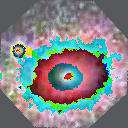

In [20]:
image,label = dataset[0]
print(f"Image shape: {image.shape}, Label: {subset_dataset.dataset.CLASS_NAMES[label]}")
sample_img = transforms.ToPILImage()(image)

sample_img